# HW5 전처리 재현 + 질문셋
이승민 · 24013735

입력: `sales_data.csv` (노트북과 같은 폴더)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게(운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

## 단계① 읽고 날짜 세 칸을 날짜로

In [2]:
df = pd.read_csv("sales_data.csv")
dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
print(df.shape)

(1030, 14)


## 단계② 중복 행 제거
결측치 세 칸(나이 51 · 만족도 30 · 도착일 5)은 수업과 같이 그대로 둔다.

In [3]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


## 단계③ 수량 > 100 인 줄의 수량을 금액 ÷ 단가로 복원

In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄:", bad.sum(), " 수량 최대:", df["quantity"].max(), " 총액 안 맞는 줄:", (diff > 1).sum())

고친 줄: 22  수량 최대: 99  총액 안 맞는 줄: 0


## 단계④ date_error 추가, sales_clean.csv 저장

In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].sum(), "건")
df.to_csv("sales_clean.csv", index=False)
print(df.shape)

147 건
(1004, 15)


## 단계⑤ 배송기간(도착일 − 배송일)은 보통 며칠인가
date_error 가 아닌 줄만 쓴다. 도착일이 빈 줄은 일수를 계산할 수 없으므로 빠진다.

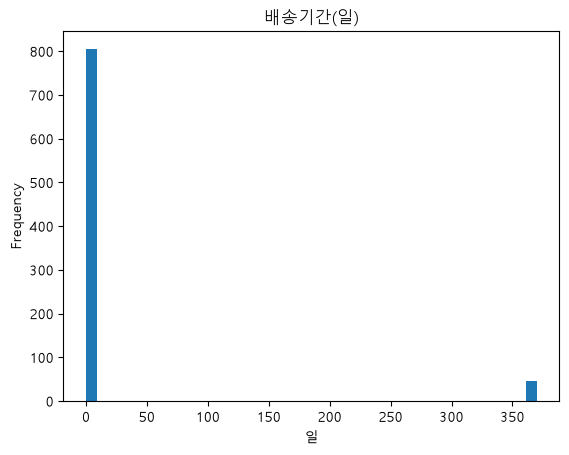

줄 수: 852  평균: 22.05  중앙값: 2.0


In [6]:
ok = df[~df["date_error"]]
days = (ok["delivery_date"] - ok["shipping_date"]).dt.days.dropna()
days.plot.hist(bins=40, title="배송기간(일)")
plt.xlabel("일")
plt.show()
print("줄 수:", len(days), " 평균:", round(days.mean(), 2), " 중앙값:", days.median())

오른쪽 끝 덩어리를 들여다본다.

In [7]:
far = days[days > 300]
print("300일 넘는 줄:", len(far))
print(far.describe())
df.loc[far.index, ["order_date", "shipping_date", "delivery_date", "status"]].head(10)

300일 넘는 줄: 47
count     47.000000
mean     366.638298
std        1.798859
min      364.000000
25%      365.000000
50%      367.000000
75%      368.000000
max      370.000000
dtype: float64


,order_date,shipping_date,delivery_date,status
11,2023-01-12,2023-01-15,2024-01-15,배송완료
20,2023-01-21,2023-01-23,2024-01-27,배송완료
29,2023-01-30,2023-02-03,2024-02-03,배송완료
41,2023-02-11,2023-02-14,2024-02-17,배송완료
68,2023-03-10,2023-03-14,2024-03-12,배송완료
99,2023-04-10,2023-04-11,2024-04-12,배송완료
110,2023-04-21,2023-04-25,2024-04-24,배송완료
131,2023-05-12,2023-05-13,2024-05-16,배송완료
165,2023-06-15,2023-06-16,2024-06-18,배송완료
192,2023-07-12,2023-07-13,2024-07-14,배송중


In [8]:
# 덩어리 47줄은 전부 364~370일. 도착일에서 1년을 빼 보면 몇 일이 되나
back = (ok.loc[far.index, "delivery_date"] - pd.DateOffset(years=1)
        - ok.loc[far.index, "shipping_date"]).dt.days
print("1년을 뺀 일수:", back.value_counts().sort_index().to_dict())
print("그래도 음수인 줄:", (back < 0).sum())

1년을 뺀 일수: {-2: 2, -1: 5, 0: 10, 1: 10, 2: 8, 3: 5, 4: 5, 5: 2}
그래도 음수인 줄: 7


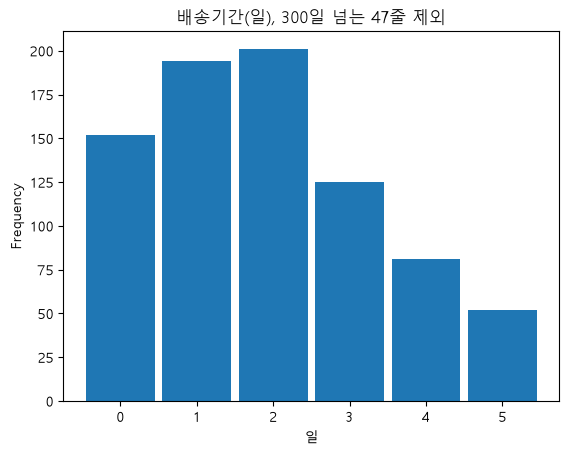

줄 수: 805  평균: 1.93  중앙값: 2.0  최소: 0.0  최대: 5.0


In [9]:
# 처리: 복원하지 않고 배송기간 계산에서만 뺀다 (df 와 sales_clean.csv 는 그대로)
normal = days[days <= 300]
normal.plot.hist(bins=range(0, 7), rwidth=0.9, align="left", title="배송기간(일), 300일 넘는 47줄 제외")
plt.xlabel("일")
plt.show()
print("줄 수:", len(normal), " 평균:", round(normal.mean(), 2), " 중앙값:", normal.median(),
      " 최소:", normal.min(), " 최대:", normal.max())

**답** 배송기간은 보통 2일이다(47줄 제외 후 805줄, 평균 1.93일 · 중앙값 2일, 0~5일). 처음 평균 22.05일이 중앙값 2일보다 크게 나온 것은 364~370일짜리 47줄이 평균만 끌어올렸기 때문이다.

이 47줄은 도착일이 정확히 1년쯤 뒤라 연도 오기로 보이지만, 1년을 빼면 7줄이 음수(-1 · -2일)가 되어 무엇이 틀렸는지 확정할 수 없다. 그래서 date_error 처럼 고치지 않고 배송기간 계산에서만 뺐다.

## 단계⑥ 만족도가 낮을수록 반품이 많은가

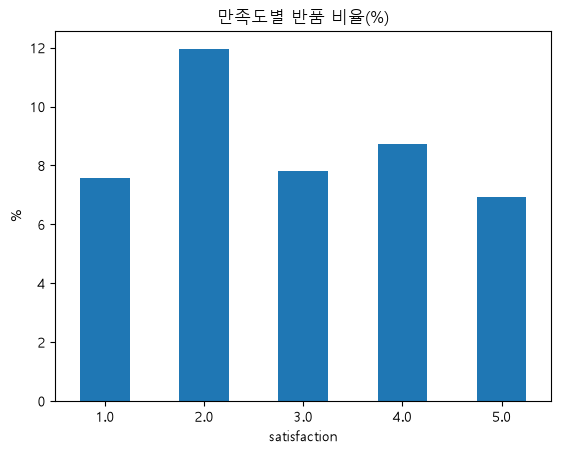

satisfaction
1.0     7.6
2.0    12.0
3.0     7.8
4.0     8.7
5.0     6.9
Name: status, dtype: float64


In [10]:
ret = (df["status"] == "반품").groupby(df["satisfaction"]).mean() * 100
ret.plot.bar(title="만족도별 반품 비율(%)", rot=0)
plt.ylabel("%")
plt.show()
print(ret.round(1))

**답** 아니다. 반품 비율은 만족도 1점 7.6% · 2점 12.0% · 3점 7.8% · 4점 8.7% · 5점 6.9%로, 만족도가 낮아질수록 늘어나지 않는다.

가장 높은 것은 2점(12.0%)이고 1점(7.6%)은 5점(6.9%)과 0.7%p 차이뿐이다. 전체 반품 비율은 8.6%이고, 만족도가 빈 30줄은 계산에서 빠졌다.

## 단계⑦ 카테고리 매출 1위의 이유는 건수 · 단가 · 수량 중 무엇인가

In [11]:
tbl = df.groupby("category").agg(
    건수=("total_sales", "count"),
    매출합_억원=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean"),
)
tbl["매출합_억원"] = tbl["매출합_억원"] / 1e8
tbl.sort_values("매출합_억원", ascending=False).round(2)

,건수,매출합_억원,평균단가,평균수량
category,,,,
가구,213,28.43,257322.91,51.04
식품,210,25.13,255232.93,47.31
전자제품,207,24.72,249651.61,47.96
도서,204,24.53,238500.64,49.50
의류,170,21.82,249447.16,51.61


**답** 매출 1위 가구(28.43억)와 5위 의류(21.82억)의 차이는 건수다: 213 vs 170건(1.25배)인데 평균단가(25.7만 vs 24.9만원)와 평균수량(51.0 vs 51.6개)은 거의 같다.

다만 2위 식품(25.13억)과는 건수(213 vs 210) · 단가(25.7만 vs 25.5만)가 비슷하고 평균수량(51.0 vs 47.3개)이 차이 나는 칸이라, 어느 한 칸이 1위를 만들었다고 하기는 어렵고 1위와 5위의 매출 차이 자체도 약 1.3배(28.43 / 21.82)로 크지 않다.